# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

Hàm `temperature_exponential()` tính nhiệt độ theo công thức $T(t)=T_0\alpha^t$ với $0<\alpha<1$. Tham số `alpha` quyết định tốc độ làm nguội: `alpha` càng gần 1, nhiệt độ giảm càng chậm.

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

Hàm `temperature_linear()` tính nhiệt độ theo $T(t)=T_0-\eta t$. `eta` càng lớn thì nhiệt độ giảm càng nhanh. Công thức có thể trả về nhiệt độ âm sau khi đi qua 0, do đó cần giới hạn về 0 hoặc dừng thuật toán ở các thí nghiệm thực tế.

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

Hàm `temperature_fast()` tính $T(t)=T_0/(1+t)$; nhiệt độ giảm mạnh ở giai đoạn đầu và tiến dần đến 0 khi số vòng lặp tăng.

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

Hàm `temperature_logarithmic()` tính $T(t)=T_0/\ln(1+t)$, chỉ áp dụng khi $t>0$. Đối với công thức đang dùng, tại $t=1$ thì $T(1)=T_0/\ln 2>T_0$. Các kết quả hội tụ lý thuyết đòi hỏi giả thiết và hệ số lịch nhiệt thích hợp, không suy ra bảo đảm nghiệm tối ưu trong số vòng lặp hữu hạn.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

Vẽ $T(t)/T_0$ trong 100 vòng lặp ($t=1,\ldots,100$), với $T_0=1$, để thấy khác biệt giữa Linear (`eta=0.01`), Exponential (`alpha=0.8` và `0.9`), Fast và Logarithmic.

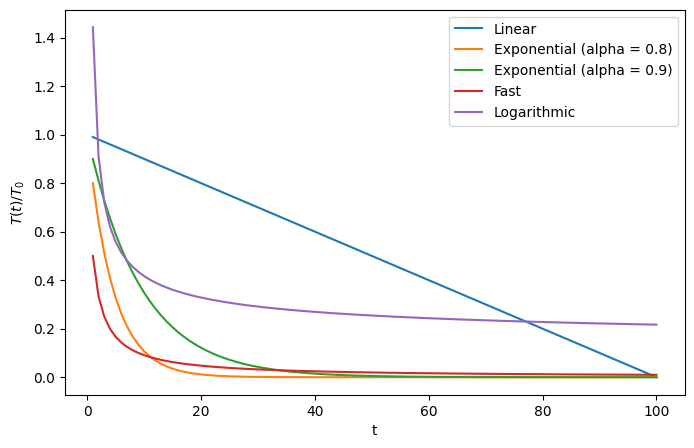

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

### Nhận xét

Qua đồ thị so sánh các lịch giảm nhiệt độ với T0 = 1 trong 100 vòng lặp, có thể thấy mỗi lịch có tốc độ giảm nhiệt khác nhau.

- **Linear:** Nhiệt độ giảm đều theo thời gian và về 0 tại vòng lặp 100 với eta = 0.01.
- **Exponential:** Nhiệt độ giảm theo hàm mũ. Với alpha = 0.8, nhiệt độ giảm nhanh hơn so với alpha = 0.9.
- **Fast:** Nhiệt độ giảm nhanh ở những vòng lặp đầu, sau đó tiếp tục giảm và tiến dần về 0.
- **Logarithmic:** Nhiệt độ giảm theo hàm logarithmic và có xu hướng giảm chậm về lâu dài. Trong thí nghiệm, lịch này duy trì nhiệt độ cao hơn Exponential và Fast ở giai đoạn cuối, nhưng không cao hơn Linear trong toàn bộ khoảng khảo sát.

Đặc biệt, với công thức Logarithmic đang sử dụng, nhiệt độ tại t = 1 lớn hơn T0 do ln(2) nhỏ hơn 1.

## Thí nghiệm 1: Thay đổi alpha

Khảo sát ảnh hưởng của hệ số `alpha` đến lịch Exponential. Giữ $T_0=1$, thời gian 1–100 vòng lặp và vẽ 4 đường với `alpha = 0.8, 0.9, 0.95, 0.99` để so sánh.

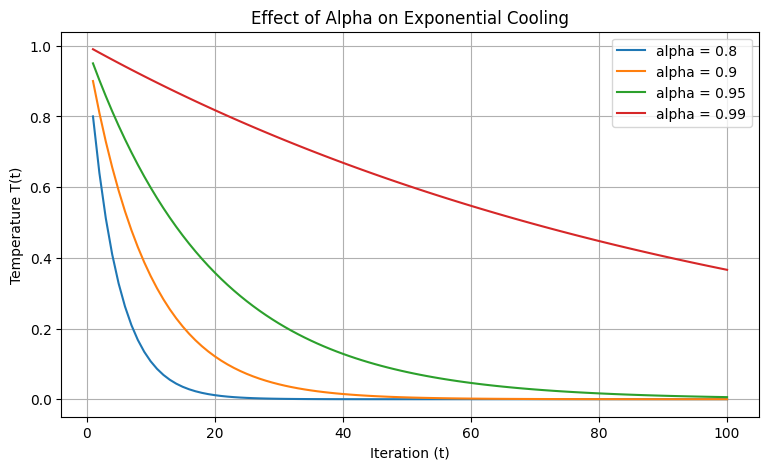

In [7]:
time = np.arange(1, 101)
T0 = 1

plt.figure(figsize=(9, 5))

for alpha in [0.8, 0.9, 0.95, 0.99]:
    T = temperature_exponential(time, T0, alpha)
    plt.plot(time, T, label=f"alpha = {alpha}")

plt.title("Effect of Alpha on Exponential Cooling")
plt.xlabel("Iteration (t)")
plt.ylabel("Temperature T(t)")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét
Khi tăng giá trị alpha từ 0.8 lên 0.99, nhiệt độ giảm chậm hơn theo số vòng lặp. Với alpha = 0.8, nhiệt độ nhanh chóng tiến gần về 0, làm giảm khả năng chấp nhận nghiệm xấu hơn. Ngược lại, alpha = 0.99 duy trì nhiệt độ cao lâu hơn, giúp thuật toán có thêm cơ hội khám phá không gian tìm kiếm. Tuy nhiên, việc giảm nhiệt quá chậm có thể làm tăng thời gian cần thiết để thuật toán hội tụ.

## Thí nghiệm 2: Thay đổi eta

Khảo sát hệ số giảm nhiệt `eta` của lịch Linear. Giữ $T_0=1$ và thử `eta = 0.005, 0.01, 0.02, 0.05`; hàm `np.maximum(T, 0)` bảo đảm nhiệt độ trên đồ thị không nhỏ hơn 0.

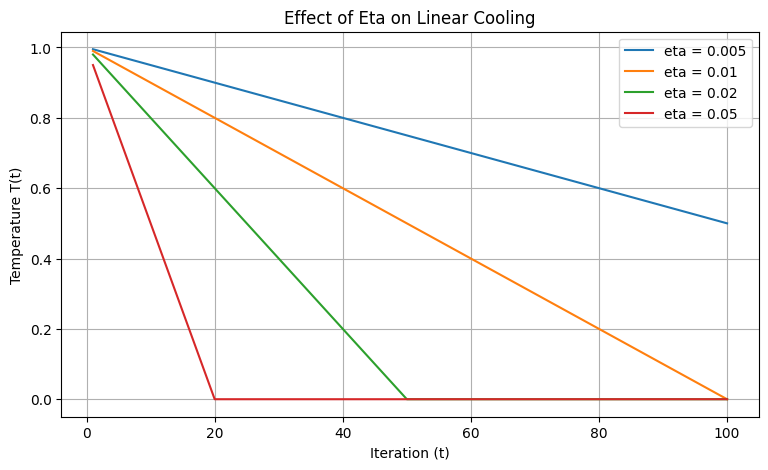

In [8]:
time = np.arange(1, 101)
T0 = 1

plt.figure(figsize=(9, 5))

for eta in [0.005, 0.01, 0.02, 0.05]:
    T = temperature_linear(time, T0, eta)
    T = np.maximum(T, 0)
    plt.plot(time, T, label=f"eta = {eta}")

plt.title("Effect of Eta on Linear Cooling")
plt.xlabel("Iteration (t)")
plt.ylabel("Temperature T(t)")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét
Khi eta tăng, tốc độ giảm nhiệt độ của lịch Linear cũng tăng. Với eta = 0.05, nhiệt độ về 0 sau 20 vòng lặp, trong khi eta = 0.005 vẫn duy trì nhiệt độ dương sau 100 vòng. Như vậy, eta nhỏ giúp thuật toán duy trì khả năng khám phá lâu hơn, còn eta lớn làm giảm nhanh xác suất chấp nhận nghiệm xấu hơn.

## Thí nghiệm 3: Thay đổi T0

Khảo sát ảnh hưởng của nhiệt độ ban đầu $T_0$. Cố định lịch Exponential với `alpha = 0.95`, thay $T_0$ lần lượt bằng `0.5, 1, 5, 10` và vẽ $T(t)$ trong 100 vòng lặp.

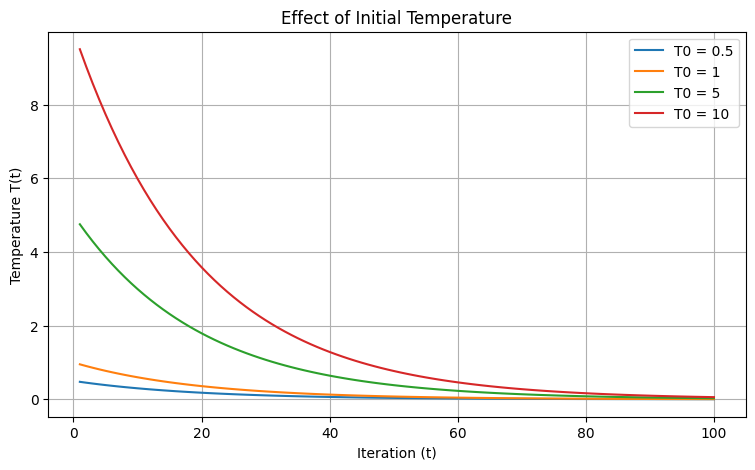

In [9]:
time = np.arange(1, 101)
alpha = 0.95

plt.figure(figsize=(9, 5))

for T0 in [0.5, 1, 5, 10]:
    T = temperature_exponential(time, T0, alpha)
    plt.plot(time, T, label=f"T0 = {T0}")

plt.title("Effect of Initial Temperature")
plt.xlabel("Iteration (t)")
plt.ylabel("Temperature T(t)")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét
Với cùng hệ số alpha = 0.95, nhiệt độ ban đầu T0 càng lớn thì nhiệt độ tại mỗi vòng lặp càng cao. Điều này giúp Simulated Annealing có xác suất chấp nhận nghiệm xấu lớn hơn trong giai đoạn đầu. Tuy nhiên, nhiệt độ ban đầu quá cao có thể khiến thuật toán thực hiện nhiều bước di chuyển không cải thiện hàm mục tiêu.

## Thí nghiệm 4: Xác suất chấp nhận nghiệm xấu hơn

Minh họa vai trò nhiệt độ đối với cơ chế chấp nhận bước đi làm tăng hàm mục tiêu trong Simulated Annealing. Với $\Delta = f_{new}-f_{current}=1>0$, xác suất là $P=\exp(-\Delta/T)$ khi $T>0$; khi nhiệt độ bằng 0, đặt xác suất bằng 0.

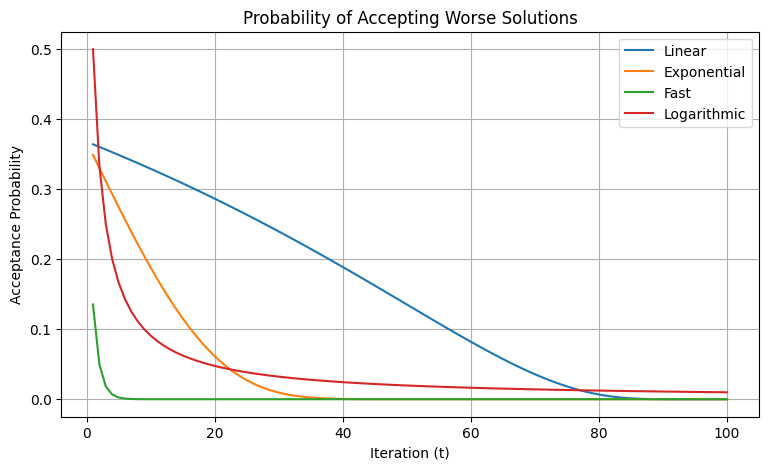

In [10]:
time = np.arange(1, 101)
T0 = 1
delta = 1

schedules = {
    "Linear": temperature_linear(time, T0, 0.01),
    "Exponential": temperature_exponential(time, T0, 0.95),
    "Fast": temperature_fast(time, T0),
    "Logarithmic": temperature_logarithmic(time, T0)
}

plt.figure(figsize=(9, 5))

for name, T in schedules.items():
    probability = np.zeros_like(T, dtype=float)
    valid = T > 0
    probability[valid] = np.exp(-delta / T[valid])
    plt.plot(time, probability, label=name)

plt.title("Probability of Accepting Worse Solutions")
plt.xlabel("Iteration (t)")
plt.ylabel("Acceptance Probability")
plt.legend()
plt.grid(True)
plt.show()

### Nhận xét

Đồ thị thể hiện sự thay đổi xác suất chấp nhận nghiệm xấu hơn theo số vòng lặp khi độ chênh lệch hàm mục tiêu được cố định ở Δ = 1.

Kết quả cho thấy xác suất chấp nhận nghiệm xấu giảm khi nhiệt độ giảm. Với tham số đang khảo sát:

- **Linear:** Duy trì xác suất chấp nhận tương đối cao trong giai đoạn đầu và giữa, sau đó giảm về 0 ở cuối quá trình.
- **Exponential:** Xác suất giảm dần theo thời gian, đặc biệt giảm mạnh khi nhiệt độ tiến gần về 0.
- **Fast:** Xác suất giảm rất nhanh từ những vòng lặp đầu, hạn chế khả năng chấp nhận nghiệm xấu.
- **Logarithmic:** Duy trì xác suất chấp nhận nghiệm xấu lâu hơn Exponential và Fast về giai đoạn cuối.

Như vậy, lịch giảm nhiệt chậm giúp Simulated Annealing duy trì khả năng khám phá không gian tìm kiếm và thoát khỏi cực trị cục bộ. Ngược lại, lịch giảm nhiệt nhanh làm thuật toán tập trung nhiều hơn vào khai thác các nghiệm hiện có nhưng có nguy cơ hội tụ sớm.

## Thí nghiệm 5: Áp dụng lịch nhiệt vào bài toán n-Queens

Trong n-Queens, mỗi phần tử vector `board` lưu chỉ số hàng của quân hậu tại một cột; cần tối thiểu hóa số cặp quân hậu tấn công nhau, với nghiệm hợp lệ khi `conflicts(board) == 0`.

In [11]:
import time
import pandas as pd

def conflicts(board):
    n = len(board)
    count = 0

    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j]:
                count += 1
            elif abs(board[i] - board[j]) == j - i:
                count += 1

    return count

### Cài đặt thuật toán Simulated Annealing

Thuật toán tạo bàn cờ ngẫu nhiên bằng `seed`, sinh láng giềng bằng cách đổi hàng của một quân hậu trong cùng cột, luôn chấp nhận bước không xấu hơn và chấp nhận bước xấu hơn với xác suất $\exp(-\Delta/T)$. Hàm lưu bàn cờ tốt nhất, số xung đột tốt nhất, số bước đã thực hiện và thời gian chạy.

In [12]:
def simulated_annealing(n, schedule, T0, steps, seed):
    rng = np.random.default_rng(seed)

    board = rng.integers(0, n, size=n)
    current_f = conflicts(board)

    best_board = board.copy()
    best_f = current_f
    iterations = 0

    start = time.perf_counter()

    for t in range(1, steps + 1):
        if best_f == 0:
            break

        T = schedule(t, T0)
        if T <= 0:
            break

        new_board = board.copy()

        col = rng.integers(0, n)
        old_row = new_board[col]

        new_row = rng.integers(0, n - 1)
        if new_row >= old_row:
            new_row += 1

        new_board[col] = new_row

        new_f = conflicts(new_board)
        delta = new_f - current_f

        iterations += 1

        if delta <= 0 or rng.random() < np.exp(-delta / T):
            board = new_board
            current_f = new_f

            if current_f < best_f:
                best_f = current_f
                best_board = board.copy()

    elapsed = time.perf_counter() - start

    return best_board, best_f, iterations, elapsed

### Thí nghiệm 5.1 – So sánh Exponential và Logarithmic trên 8-Queens

Tiếp theo áp dụng hai lịch nhiệt: Exponential với `alpha=0.995` và Logarithmic với công thức đã định nghĩa. Mỗi lịch chạy 30 lần (`seed` từ 0 đến 29), dùng `n=8`, $T_0=5$ và tối đa 3.000 bước. Bảng in ra gồm số xung đột trung bình, tỉ lệ thành công, số vòng lặp trung bình và thời gian trung bình (ms).

In [13]:
schedule_functions = {
    "Exponential": lambda t, T0:
        temperature_exponential(t, T0, 0.995),

    "Logarithmic": lambda t, T0:
        temperature_logarithmic(t, T0)
}

results = []

for name, schedule in schedule_functions.items():
    for seed in range(30):
        board, best_f, iterations, elapsed = simulated_annealing(
            n=8,
            schedule=schedule,
            T0=5,
            steps=3000,
            seed=seed
        )

        results.append({
            "Schedule": name,
            "Seed": seed,
            "Best Conflicts": best_f,
            "Success": int(best_f == 0),
            "Iterations": iterations,
            "Time (ms)": elapsed * 1000
        })

df = pd.DataFrame(results)

summary = df.groupby("Schedule").agg(
    Avg_Conflicts=("Best Conflicts", "mean"),
    Success_Rate=("Success", "mean"),
    Avg_Iterations=("Iterations", "mean"),
    Avg_Time_ms=("Time (ms)", "mean")
)

summary["Success_Rate"] *= 100

print(summary.round(3))

             Avg_Conflicts  Success_Rate  Avg_Iterations  Avg_Time_ms
Schedule                                                             
Exponential          0.000       100.000        1153.300       25.172
Logarithmic          0.367        63.333        2031.933       43.929


### Trực quan hóa tỉ lệ thành công trên 8-Queens

Sử dụng cột `Success_Rate` từ bảng `summary` để vẽ biểu đồ cột so sánh tỉ lệ tìm được nghiệm không xung đột của hai lịch nhiệt.

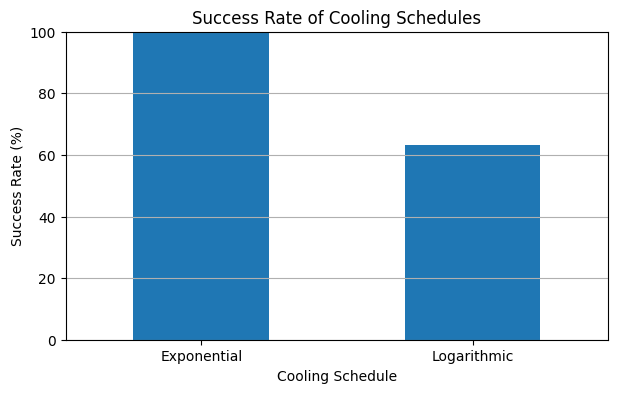

In [14]:
summary["Success_Rate"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Success Rate of Cooling Schedules"
)

plt.xlabel("Cooling Schedule")
plt.ylabel("Success Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

### Nhận xét kết quả Simulated Annealing

Thí nghiệm được thực hiện trên bài toán 8-Queens với 30 random seed, nhiệt độ ban đầu T0 = 5 và tối đa 3000 vòng lặp. Hai lịch giảm nhiệt độ được sử dụng là Exponential (alpha = 0.995) và Logarithmic.

**1. Chất lượng nghiệm**

Lịch Exponential đạt tỉ lệ thành công 100%, tương ứng cả 30 lần chạy đều tìm được nghiệm không xung đột. Trong khi đó, Logarithmic đạt tỉ lệ thành công 63.33%, tương ứng 19/30 lần chạy.

Số xung đột trung bình của Exponential là 0, thấp hơn Logarithmic với 0.367. Điều này cho thấy Exponential tạo ra nghiệm tốt hơn trong thí nghiệm hiện tại.

**2. Số vòng lặp**

Exponential sử dụng trung bình khoảng 1153 vòng lặp, trong khi Logarithmic sử dụng khoảng 2032 vòng lặp. Như vậy, Exponential cần ít vòng lặp hơn để kết thúc quá trình tìm kiếm trong điều kiện khảo sát.

**3. Thời gian thực thi**

Thời gian chạy trung bình của Exponential là 25.172 ms, thấp hơn Logarithmic với 43.929 ms. Sự khác biệt này phù hợp với việc Exponential sử dụng ít vòng lặp hơn.

**4. Đánh giá chung**

Trong thí nghiệm này, lịch Exponential cho kết quả tốt hơn cả về chất lượng nghiệm, tỉ lệ thành công, số vòng lặp và thời gian thực thi.

Lịch Logarithmic duy trì nhiệt độ cao hơn ở giai đoạn cuối, giúp thuật toán có khả năng tiếp tục khám phá không gian nghiệm. Tuy nhiên, việc duy trì nhiệt độ cao không đồng nghĩa với việc luôn tìm được nghiệm tốt hơn trong một ngân sách vòng lặp hữu hạn.

Kết quả trên chỉ phản ánh các tham số và dữ liệu thử nghiệm đã lựa chọn, không chứng minh Exponential luôn tốt hơn Logarithmic trong mọi bài toán.

## Thí nghiệm 6: So sánh hai lịch nhiệt trên 4-Queens và 8-Queens

Kiểm tra tác động của kích thước bài toán. Chạy lại cả hai lịch nhiệt cho `n=4` và `n=8`, mỗi cấu hình với 30 seed, giữ $T_0=5$ và giới hạn 3.000 bước.

In [15]:
results_compare = []

for n in [4, 8]:
    for name, schedule in schedule_functions.items():
        for seed in range(30):
            board, best_f, iterations, elapsed = simulated_annealing(
                n=n,
                schedule=schedule,
                T0=5,
                steps=3000,
                seed=seed
            )

            results_compare.append({
                "n": n,
                "Schedule": name,
                "Success": int(best_f == 0),
                "Best Conflicts": best_f,
                "Iterations": iterations,
                "Time (ms)": elapsed * 1000
            })

df_compare = pd.DataFrame(results_compare)

summary_compare = df_compare.groupby(
    ["n", "Schedule"]
).agg(
    Success_Rate=("Success", "mean"),
    Avg_Conflicts=("Best Conflicts", "mean"),
    Avg_Iterations=("Iterations", "mean"),
    Avg_Time_ms=("Time (ms)", "mean")
)

summary_compare["Success_Rate"] *= 100

print(summary_compare.round(3))

               Success_Rate  Avg_Conflicts  Avg_Iterations  Avg_Time_ms
n Schedule                                                             
4 Exponential       100.000          0.000         114.100        0.921
  Logarithmic       100.000          0.000          63.167        0.618
8 Exponential       100.000          0.000        1153.300       29.101
  Logarithmic        63.333          0.367        2031.933       47.201


### Nhận xét kết quả thí nghiệm n=4 và n=8

Với `n=4`, cả hai lịch đều tìm được nghiệm hợp lệ trong mọi lần chạy; Logarithmic dùng ít bước hơn. Khi tăng lên `n=8`, Exponential cho kết quả tốt hơn trong cấu hình khảo sát. Thời gian chạy là số đo thực nghiệm, có thể thay đổi theo máy và lần chạy; không nên khẳng định lịch nào luôn tối ưu.

### Trực quan hóa tỉ lệ thành công trên 4-Queens và 8-Queens

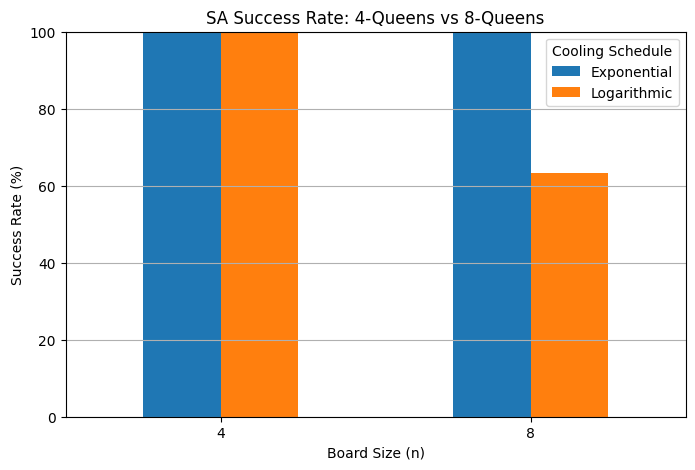

In [16]:
success_data = (
    df_compare.groupby(["n", "Schedule"])["Success"]
    .mean()
    .mul(100)
    .unstack()
)

success_data.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("SA Success Rate: 4-Queens vs 8-Queens")
plt.xlabel("Board Size (n)")
plt.ylabel("Success Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Cooling Schedule")
plt.grid(axis="y")
plt.show()

### Nhận xét

Biểu đồ cho thấy cả hai lịch đều đạt 100% ở 4-Queens, nhưng khi chuyển sang 8-Queens, Exponential vẫn đạt 100% trong khi Logarithmic giảm còn 63,333%. Như vậy, ở điều kiện thí nghiệm hiện tại, mức độ khó của bài toán tăng đã tạo ra khác biệt rõ giữa hai lịch nhiệt. Tuy nhiên, chỉ khảo sát hai kích thước bàn cờ và 30 seed nên chưa đủ để kết luận xu hướng hiệu năng tổng quát với mọi `n`. 

## Kết luận

Qua quá trình khảo sát các lịch giảm nhiệt độ Linear, Exponential, Fast và Logarithmic, có thể thấy tốc độ giảm nhiệt ảnh hưởng trực tiếp đến xác suất chấp nhận nghiệm xấu hơn trong Simulated Annealing.

Các tham số alpha, eta và T0 đóng vai trò quan trọng trong việc điều chỉnh sự cân bằng giữa khám phá (exploration) và khai thác (exploitation). Nhiệt độ giảm quá nhanh có thể khiến thuật toán mắc kẹt tại cực trị cục bộ, trong khi nhiệt độ giảm quá chậm có thể làm tăng chi phí tìm kiếm.

Khi áp dụng Exponential và Logarithmic cho bài toán 8-Queens, kết quả thí nghiệm ban đầu cho thấy Exponential đạt tỉ lệ thành công cao hơn và thời gian chạy trung bình thấp hơn. Điều này cho thấy việc lựa chọn lịch giảm nhiệt phù hợp cần dựa trên đặc điểm bài toán, tham số và ngân sách tính toán.

Nhìn chung, không có một lịch giảm nhiệt nào luôn tối ưu trong mọi trường hợp. Việc thực nghiệm và điều chỉnh tham số là cần thiết để cải thiện hiệu quả của Simulated Annealing.

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)